In [1]:
import gymnasium as gym
import math
import random
import matplotlib
import matplotlib.pyplot as plt
from collections import namedtuple, deque
from itertools import count

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F

env = gym.make("CartPole-v1")

# set up matplotlib
is_ipython = 'inline' in matplotlib.get_backend()
if is_ipython:
    from IPython import display

plt.ion()

# if GPU is to be used
device = torch.device(
    "cuda" if torch.cuda.is_available() else
    "mps" if torch.backends.mps.is_available() else
    "cpu"
)

# Notebook 03 - DQN with PyTorch, step by step

Goal: understand what each PyTorch/DQN function is doing by looking at concrete inputs, outputs, tensor shapes, and small examples.

CartPole observation = 4 numbers: cart position, cart velocity, pole angle, pole angular velocity.

CartPole actions = 2 integers: `0` means push left, `1` means push right.

The DQN does not directly output an action. It outputs one Q-value per action, for example `[[1.2, 0.7]]`. The action is selected with `argmax`, so action `0` wins because `1.2 > 0.7`.

## Replay memory

DQN learns from transitions stored as `(state, action, next_state, reward)`.

Instead of training only on the latest transition, `ReplayMemory.sample` picks random older transitions. This breaks the strong correlation between consecutive game frames and makes training more stable.

In [2]:
Transition = namedtuple('Transition',
                        ('state', 'action', 'next_state', 'reward'))


class ReplayMemory(object):

    def __init__(self, capacity):
        self.memory = deque([], maxlen=capacity)

    def push(self, *args):
        """Save a transition"""
        self.memory.append(Transition(*args))

    def sample(self, batch_size):
        return random.sample(self.memory, batch_size)

    def __len__(self):
        return len(self.memory)

## Neural network used as a Q-function

`nn.Module` is the PyTorch base class for neural networks.

`nn.Linear(in_features, out_features)` applies `x @ weight.T + bias`.

`F.relu` replaces negative values by `0`, which adds non-linearity.

The final layer has `n_actions` outputs. For CartPole this is `2`, so each row is `[Q(left), Q(right)]`.

In [3]:
class DQN(nn.Module):

    def __init__(self, n_observations, n_actions):
        super(DQN, self).__init__()
        self.layer1 = nn.Linear(n_observations, 128)
        self.layer2 = nn.Linear(128, 128)
        self.layer3 = nn.Linear(128, n_actions)

    # Called with either one element to determine next action, or a batch
    # during optimization. Returns tensor([[left0exp,right0exp]...]).
    def forward(self, x):
        x = F.relu(self.layer1(x))
        x = F.relu(self.layer2(x))
        return self.layer3(x)

## PyTorch methods used in this DQN

Run this cell before training. It uses tiny tensors so you can see exactly what each method receives and returns.

In [4]:
torch.manual_seed(0)

print('device:', device)

# torch.tensor converts Python or NumPy values into a PyTorch tensor.
raw_state = [0.01, 0.02, -0.03, 0.04]
state_1d = torch.tensor(raw_state, dtype=torch.float32, device=device)
print('state_1d:', state_1d)
print('state_1d.shape:', state_1d.shape)

device: cuda
state_1d: tensor([ 0.0100,  0.0200, -0.0300,  0.0400], device='cuda:0')
state_1d.shape: torch.Size([4])


In [5]:

# unsqueeze(0) adds a batch dimension: one state with four features.
state_batch = state_1d.unsqueeze(0)
print('state_batch:', state_batch)
print('state_batch.shape:', state_batch.shape)

state_batch: tensor([[ 0.0100,  0.0200, -0.0300,  0.0400]], device='cuda:0')
state_batch.shape: torch.Size([1, 4])


In [6]:

# nn.Linear maps input features to output features.
linear = nn.Linear(4, 2).to(device)
linear_output = linear(state_batch)
print('linear_output shape:', linear_output.shape)
print('linear_output example:', linear_output)

linear_output shape: torch.Size([1, 2])
linear_output example: tensor([[-0.0414,  0.1492]], device='cuda:0', grad_fn=<AddmmBackward0>)


In [7]:

# ReLU keeps positive values and turns negative values into 0.
values = torch.tensor([[-2.0, -0.5, 0.0, 3.0]], device=device)
print('relu input:', values)
print('relu output:', F.relu(values))

relu input: tensor([[-2.0000, -0.5000,  0.0000,  3.0000]], device='cuda:0')
relu output: tensor([[0., 0., 0., 3.]], device='cuda:0')


In [8]:

# DQN forward pass: input [batch_size, 4], output [batch_size, 2].
demo_net = DQN(n_observations=4, n_actions=2).to(device)
q_values = demo_net(state_batch)
print('DQN q_values:', q_values)
print('DQN q_values.shape:', q_values.shape)

DQN q_values: tensor([[ 0.0295, -0.0190]], device='cuda:0', grad_fn=<AddmmBackward0>)
DQN q_values.shape: torch.Size([1, 2])


In [9]:

# max(1) looks across columns/actions for each row/state.
best = q_values.max(1)
print('max values:', best.values)
print('max indices/actions:', best.indices)
print('action tensor for env.step:', best.indices.view(1, 1))

max values: tensor([0.0295], device='cuda:0', grad_fn=<MaxBackward0>)
max indices/actions: tensor([0], device='cuda:0')
action tensor for env.step: tensor([[0]], device='cuda:0')


### Microscope: `policy_net(state).max(1).indices.view(1, 1)`

This line is used when the agent exploits, meaning it chooses the action predicted to have the highest Q-value.

1. `policy_net(state)` returns Q-values for all actions. Shape: `[1, 2]`. Example: `[[0.8, 1.4]]`.
2. `.max(1)` searches dimension `1`, the action dimension. It returns both the best value and the index of that value.
3. `.indices` keeps only the index/action, not the Q-value. Example: `[1]`.
4. `.view(1, 1)` reshapes `[1]` into `[[1]]`, matching the action tensor shape used later by `gather(1, action_batch)`.

In [10]:
# Same logic as: policy_net(state).max(1).indices.view(1, 1)
fake_policy_output = torch.tensor([[0.8, 1.4]], device=device)

step_1_q_values = fake_policy_output
step_2_max_result = step_1_q_values.max(1)
step_3_action_index = step_2_max_result.indices
step_4_action_tensor = step_3_action_index.view(1, 1)

print('1. policy_net(state) gives Q-values:', step_1_q_values)
print('   shape:', step_1_q_values.shape)
print('2. .max(1) values:', step_2_max_result.values)
print('2. .max(1) indices:', step_2_max_result.indices)
print('3. .indices gives selected action:', step_3_action_index)
print('   shape:', step_3_action_index.shape)
print('4. .view(1, 1) gives action tensor:', step_4_action_tensor)
print('   shape:', step_4_action_tensor.shape)
print('action.item() for env.step:', step_4_action_tensor.item())

1. policy_net(state) gives Q-values: tensor([[0.8000, 1.4000]], device='cuda:0')
   shape: torch.Size([1, 2])
2. .max(1) values: tensor([1.4000], device='cuda:0')
2. .max(1) indices: tensor([1], device='cuda:0')
3. .indices gives selected action: tensor([1], device='cuda:0')
   shape: torch.Size([1])
4. .view(1, 1) gives action tensor: tensor([[1]], device='cuda:0')
   shape: torch.Size([1, 1])
action.item() for env.step: 1


In [11]:

# gather(1, actions) selects the Q-value of the action actually taken.
all_q = torch.tensor([[1.2, 0.7], [0.1, 2.5], [3.0, 2.0]], device=device)
actions = torch.tensor([[0], [1], [0]], device=device)
print('all_q:', all_q)
print('actions:', actions)
print('selected Q-values with gather:', all_q.gather(1, actions))

all_q: tensor([[1.2000, 0.7000],
        [0.1000, 2.5000],
        [3.0000, 2.0000]], device='cuda:0')
actions: tensor([[0],
        [1],
        [0]], device='cuda:0')
selected Q-values with gather: tensor([[1.2000],
        [2.5000],
        [3.0000]], device='cuda:0')


In [12]:
# no_grad disables gradient tracking for inference/target computation.
with torch.no_grad():
    inference_q = demo_net(state_batch)
print('requires_grad outside training target:', inference_q.requires_grad)

requires_grad outside training target: False


In [13]:
# BATCH_SIZE is the number of transitions sampled from the replay buffer
# GAMMA is the discount factor as mentioned in the previous section
# EPS_START is the starting value of epsilon
# EPS_END is the final value of epsilon
# EPS_DECAY controls the rate of exponential decay of epsilon, higher means a slower decay
# TAU is the update rate of the target network
# LR is the learning rate of the ``AdamW`` optimizer
# TRAINING_TIMESTEPS is the shared environment-step budget used by manual DQN and SB3 DQN

BATCH_SIZE = 128
GAMMA = 0.99
EPS_START = 0.9
EPS_END = 0.01
EPS_DECAY = 2500
TAU = 0.005
LR = 3e-4
TRAINING_TIMESTEPS = 25_000


# Get number of actions from gym action space
n_actions = env.action_space.n
# Get the number of state observations 
state, info = env.reset()
n_observations = len(state)

policy_net = DQN(n_observations, n_actions).to(device)
target_net = DQN(n_observations, n_actions).to(device)
target_net.load_state_dict(policy_net.state_dict())

optimizer = optim.AdamW(policy_net.parameters(), lr=LR, amsgrad=True)
memory = ReplayMemory(10000)


steps_done = 0


def select_action(state):
    global steps_done
    sample = random.random()
    eps_threshold = EPS_END + (EPS_START - EPS_END) * \
        math.exp(-1. * steps_done / EPS_DECAY)
    steps_done += 1
    if sample > eps_threshold:
        with torch.no_grad():
            # t.max(1) will return the largest column value of each row.
            # second column on max result is index of where max element was
            # found, so we pick action with the larger expected reward.
            return policy_net(state).max(1).indices.view(1, 1)
    else:
        return torch.tensor([[env.action_space.sample()]], device=device, dtype=torch.long)


episode_durations = []


def plot_durations(show_result=False):
    plt.figure(1)
    durations_t = torch.tensor(episode_durations, dtype=torch.float)
    if show_result:
        plt.title('Result')
    else:
        plt.clf()
        plt.title('Training...')
    plt.xlabel('Episode')
    plt.ylabel('Duration')
    plt.plot(durations_t.numpy())
    # Take 100 episode averages and plot them too
    if len(durations_t) >= 100:
        means = durations_t.unfold(0, 100, 1).mean(1).view(-1)
        means = torch.cat((torch.zeros(99), means))
        plt.plot(means.numpy())

    plt.pause(0.001)  # pause a bit so that plots are updated
    if is_ipython:
        if not show_result:
            display.display(plt.gcf())
            display.clear_output(wait=True)
        else:
            display.display(plt.gcf())

## Mini replay-batch example

The optimizer trains on a batch of transitions. This small example mirrors the tensor operations used inside `optimize_model`, but with only 3 transitions so every shape is easy to inspect.

In [14]:
demo_memory = ReplayMemory(10)

s0 = torch.tensor([[0.0, 0.1, 0.2, 0.3]], device=device)
s1 = torch.tensor([[1.0, 1.1, 1.2, 1.3]], device=device)
s2 = torch.tensor([[2.0, 2.1, 2.2, 2.3]], device=device)
s3 = torch.tensor([[3.0, 3.1, 3.2, 3.3]], device=device)

demo_memory.push(s0, torch.tensor([[0]], device=device), s1, torch.tensor([1.0], device=device))
demo_memory.push(s1, torch.tensor([[1]], device=device), s2, torch.tensor([0.5], device=device))
demo_memory.push(s2, torch.tensor([[0]], device=device), None, torch.tensor([-1.0], device=device))

transitions = demo_memory.sample(3)
batch = Transition(*zip(*transitions))

non_final_mask = torch.tensor(tuple(s is not None for s in batch.next_state), device=device, dtype=torch.bool)
non_final_next_states = torch.cat([s for s in batch.next_state if s is not None])
state_batch = torch.cat(batch.state)
action_batch = torch.cat(batch.action)
reward_batch = torch.cat(batch.reward)

print('len(memory):', len(demo_memory))
print('non_final_mask:', non_final_mask)
print('state_batch shape:', state_batch.shape, state_batch)
print('action_batch shape:', action_batch.shape, action_batch)
print('reward_batch shape:', reward_batch.shape, reward_batch)
print('non_final_next_states shape:', non_final_next_states.shape, non_final_next_states)

demo_q = torch.tensor([[10.0, 20.0], [30.0, 40.0], [50.0, 60.0]], device=device)
print('demo_q:', demo_q)
print('Q-values for taken actions:', demo_q.gather(1, action_batch))

len(memory): 3
non_final_mask: tensor([ True,  True, False], device='cuda:0')
state_batch shape: torch.Size([3, 4]) tensor([[0.0000, 0.1000, 0.2000, 0.3000],
        [1.0000, 1.1000, 1.2000, 1.3000],
        [2.0000, 2.1000, 2.2000, 2.3000]], device='cuda:0')
action_batch shape: torch.Size([3, 1]) tensor([[0],
        [1],
        [0]], device='cuda:0')
reward_batch shape: torch.Size([3]) tensor([ 1.0000,  0.5000, -1.0000], device='cuda:0')
non_final_next_states shape: torch.Size([2, 4]) tensor([[1.0000, 1.1000, 1.2000, 1.3000],
        [2.0000, 2.1000, 2.2000, 2.3000]], device='cuda:0')
demo_q: tensor([[10., 20.],
        [30., 40.],
        [50., 60.]], device='cuda:0')
Q-values for taken actions: tensor([[10.],
        [40.],
        [50.]], device='cuda:0')


### Microscope: `batch = Transition(*zip(*transitions))`

`transitions` starts as a list of complete experiences. Each item looks like `(state, action, next_state, reward)`.

DQN optimization needs the opposite structure: all states together, all actions together, all next states together, all rewards together.

This expression transposes the structure:

1. `zip(*transitions)` groups by field: `(all_states, all_actions, all_next_states, all_rewards)`.
2. `*zip(...)` unpacks those four groups as arguments.
3. `Transition(...)` names those groups as `.state`, `.action`, `.next_state`, and `.reward`.

In [15]:
# Same logic as: batch = Transition(*zip(*transitions))
toy_transitions = [
    Transition('state_0', 'action_0', 'next_state_0', 'reward_0'),
    Transition('state_1', 'action_1', 'next_state_1', 'reward_1'),
    Transition('state_2', 'action_2', None, 'reward_2'),
]

print('Original list: one full transition per row')
for transition in toy_transitions:
    print(transition)

Original list: one full transition per row
Transition(state='state_0', action='action_0', next_state='next_state_0', reward='reward_0')
Transition(state='state_1', action='action_1', next_state='next_state_1', reward='reward_1')
Transition(state='state_2', action='action_2', next_state=None, reward='reward_2')


In [16]:

zipped = list(zip(*toy_transitions))
print('\nAfter zip(*toy_transitions): grouped by column/field')
for group in zipped:
    print(group)

batch = Transition(*zipped)
print('\nAfter Transition(*zipped): named groups')
print('batch.state:', batch.state)
print('batch.action:', batch.action)
print('batch.next_state:', batch.next_state)
print('batch.reward:', batch.reward)


After zip(*toy_transitions): grouped by column/field
('state_0', 'state_1', 'state_2')
('action_0', 'action_1', 'action_2')
('next_state_0', 'next_state_1', None)
('reward_0', 'reward_1', 'reward_2')

After Transition(*zipped): named groups
batch.state: ('state_0', 'state_1', 'state_2')
batch.action: ('action_0', 'action_1', 'action_2')
batch.next_state: ('next_state_0', 'next_state_1', None)
batch.reward: ('reward_0', 'reward_1', 'reward_2')


## What `optimize_model` computes

For each sampled transition, the network predicts `Q(state, action_taken)`.

The training target is the Bellman target: `reward + GAMMA * max_a Q_target(next_state, a)`.

If the episode ended, `next_state` is `None`, so the future value is `0` and the target is only the reward.

`SmoothL1Loss` is Huber loss. It behaves like squared error near zero and like absolute error for large mistakes, making DQN less sensitive to unstable targets.

In [17]:
def optimize_model():
    if len(memory) < BATCH_SIZE:
        return
    transitions = memory.sample(BATCH_SIZE)
    # Transpose the batch (see https://stackoverflow.com/a/19343/3343043 for
    # detailed explanation). This converts batch-array of Transitions
    # to Transition of batch-arrays.
    batch = Transition(*zip(*transitions))

    # Compute a     non-final states and concatenate the batch elements
    # (a final state would've been the one after which simulation ended)
    non_final_mask = torch.tensor(tuple(map(lambda s: s is not None,
                                          batch.next_state)), device=device, dtype=torch.bool)
    non_final_next_states = torch.cat([s for s in batch.next_state
                                                if s is not None])
    state_batch = torch.cat(batch.state)
    action_batch = torch.cat(batch.action)
    reward_batch = torch.cat(batch.reward)

    # Compute Q(s_t, a) - the model computes Q(s_t), then we select the
    # columns of actions taken. These are the actions which would've been taken
    # for each batch state according to policy_net
    state_action_values = policy_net(state_batch).gather(1, action_batch)

    # Compute V(s_{t+1}) for all next states.
    # Expected values of actions for non_final_next_states are computed based
    # on the "older" target_net; selecting their best reward with max(1).values
    # This is merged based on the mask, such that we'll have either the expected
    # state value or 0 in case the state was final.
    next_state_values = torch.zeros(BATCH_SIZE, device=device)
    with torch.no_grad():
        next_state_values[non_final_mask] = target_net(non_final_next_states).max(1).values
    # Compute the expected Q values
    expected_state_action_values = (next_state_values * GAMMA) + reward_batch

    # Compute Huber loss
    criterion = nn.SmoothL1Loss()
    loss = criterion(state_action_values, expected_state_action_values.unsqueeze(1))

    # Optimize the model
    optimizer.zero_grad()
    loss.backward()
    # In-place gradient clipping
    torch.nn.utils.clip_grad_value_(policy_net.parameters(), 100)
    optimizer.step()

## Loss, gradients, optimizer, and target update

This example shows the same math as DQN training without running the environment. The numbers are artificial, but the shapes match the real code.

In [18]:
# Predicted Q(state, action_taken) from policy_net. Shape: [batch_size, 1]
predicted = torch.tensor([[1.0], [2.0], [4.0]], device=device, requires_grad=True)

# Best target-network value for next states. Terminal transition gets 0.
next_state_values = torch.tensor([3.0, 0.0, 10.0], device=device)
rewards = torch.tensor([1.0, -1.0, 0.5], device=device)
expected = rewards + GAMMA * next_state_values

criterion = nn.SmoothL1Loss()
loss = criterion(predicted, expected.unsqueeze(1))
print('predicted:', predicted)
print('expected:', expected.unsqueeze(1))
print('SmoothL1Loss:', loss)

# backward computes gradients: how each predicted value should move to reduce loss.
loss.backward()
print('gradient on predicted:', predicted.grad)

# A tiny optimizer example with one Linear layer.
tiny = nn.Linear(1, 1).to(device)
tiny_optimizer = optim.AdamW(tiny.parameters(), lr=0.1)
x = torch.tensor([[1.0], [2.0]], device=device)
y = torch.tensor([[2.0], [4.0]], device=device)
before = tiny.weight.detach().clone()
tiny_loss = F.mse_loss(tiny(x), y)
tiny_optimizer.zero_grad()
tiny_loss.backward()
torch.nn.utils.clip_grad_value_(tiny.parameters(), 100)
tiny_optimizer.step()
after = tiny.weight.detach().clone()
print('optimizer changed weight from', before, 'to', after)

# Soft target update: target slowly moves toward policy.
policy_weight = torch.tensor([10.0], device=device)
target_weight = torch.tensor([2.0], device=device)
soft_updated = policy_weight * TAU + target_weight * (1 - TAU)
print('soft update:', soft_updated, '= policy * TAU + target * (1 - TAU)')

predicted: tensor([[1.],
        [2.],
        [4.]], device='cuda:0', requires_grad=True)
expected: tensor([[ 3.9700],
        [-1.0000],
        [10.4000]], device='cuda:0')
SmoothL1Loss: tensor(3.6233, device='cuda:0', grad_fn=<SmoothL1LossBackward0>)
gradient on predicted: tensor([[-0.3333],
        [ 0.3333],
        [-0.3333]], device='cuda:0')
optimizer changed weight from tensor([[-0.2629]], device='cuda:0') to tensor([[-0.1626]], device='cuda:0')
soft update: tensor([2.0400], device='cuda:0') = policy * TAU + target * (1 - TAU)


Complete: manual DQN trained for 25000 env steps across 209 episodes


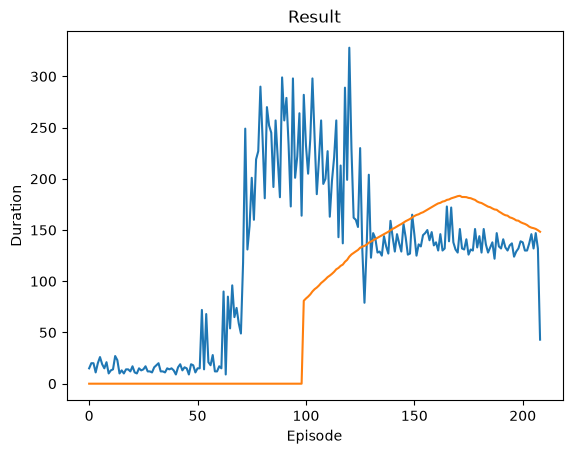

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

In [19]:
manual_timesteps = 0
manual_episode_index = 0

while manual_timesteps < TRAINING_TIMESTEPS:
    # Initialize the environment and get its state
    state, info = env.reset()
    state = torch.tensor(state, dtype=torch.float32, device=device).unsqueeze(0)

    for t in count():
        action = select_action(state)
        observation, reward, terminated, truncated, _ = env.step(action.item())
        manual_timesteps += 1
        reward = torch.tensor([reward], device=device)
        done = terminated or truncated

        if terminated:
            next_state = None
        else:
            next_state = torch.tensor(observation, dtype=torch.float32, device=device).unsqueeze(0)

        # Store the transition in memory
        memory.push(state, action, next_state, reward)

        # Move to the next state
        state = next_state

        # Perform one step of the optimization (on the policy network)
        optimize_model()

        # Soft update of the target network's weights
        # theta_target <- tau * theta_policy + (1 - tau) * theta_target
        target_net_state_dict = target_net.state_dict()
        policy_net_state_dict = policy_net.state_dict()
        for key in policy_net_state_dict:
            target_net_state_dict[key] = policy_net_state_dict[key]*TAU + target_net_state_dict[key]*(1-TAU)
        target_net.load_state_dict(target_net_state_dict)

        if done or manual_timesteps >= TRAINING_TIMESTEPS:
            episode_durations.append(t + 1)
            manual_episode_index += 1
            plot_durations()
            break

print(f'Complete: manual DQN trained for {manual_timesteps} env steps across {manual_episode_index} episodes')
plot_durations(show_result=True)
plt.ioff()
plt.show()

## Stable-Baselines3 DQN: train, evaluate, save

This final section uses the `DQN` implementation from Stable-Baselines3, not the manual PyTorch `DQN` class defined earlier.

Required outputs:

1. A DQN model trained on `CartPole-v1`.
2. Training for `TRAINING_TIMESTEPS = 25_000` environment interactions, the same budget as the manual DQN.
3. Mean and standard deviation reward over 100 evaluation episodes.
4. A saved model file: `dqn_cartpole.zip`.

In [39]:
import gymnasium as gym
from stable_baselines3 import DQN as SB3DQN
from stable_baselines3.common.evaluation import evaluate_policy
from stable_baselines3.common.monitor import Monitor

# This is Stable-Baselines3 DQN, not the manual PyTorch DQN class defined above.
sb3_env = gym.make("CartPole-v1")
eval_env = Monitor(gym.make("CartPole-v1"))

model = SB3DQN(
    "MlpPolicy", 
    sb3_env, 
    learning_rate=0.0003, 
    batch_size=128,
    tau=0.005,
    gamma=0.99,
    target_update_interval=1,
    verbose=0, 
    tensorboard_log="./logs/"
)

# total_timesteps is the number of environment interactions, not episodes.
model.learn(total_timesteps=TRAINING_TIMESTEPS)

mean_reward, std_reward = evaluate_policy(
    model,
    eval_env,
    n_eval_episodes=100,
    deterministic=True,
)
print(f"Mean reward over 100 episodes: {mean_reward:.2f} +/- {std_reward:.2f}")

model.save("dqn_cartpole")
print("Saved model to dqn_cartpole.zip")

sb3_env.close()
eval_env.close()

Mean reward over 100 episodes: 122.00 +/- 3.45
Saved model to dqn_cartpole.zip


## Compare manual PyTorch DQN vs Stable-Baselines3 DQN

A fair comparison uses the same environment, the same training budget, and the same evaluation protocol. Here both agents are trained for `TRAINING_TIMESTEPS = 25_000` environment interactions and evaluated on `CartPole-v1` over 100 episodes with greedy/deterministic actions.

What this comparison shows:

1. Manual PyTorch DQN is useful for understanding replay memory, Q-values, Bellman targets, gradients, and target-network updates.
2. Stable-Baselines3 DQN is useful for reliable training, logging, evaluation helpers, and saving/loading with much less code.
3. The shared budget is `TRAINING_TIMESTEPS`, which counts `env.step(...)` interactions, not episodes.

Agent                     | Training budget                             | Mean reward |     Std | Saved model
-------------------------------------------------------------------------------------------------------------------
Manual PyTorch DQN        | 25000 env steps                             |      136.00 |    6.54 | manual_dqn_cartpole.pt
Stable-Baselines3 DQN     | 25000 env steps                             |       75.20 |    9.05 | dqn_cartpole.zip


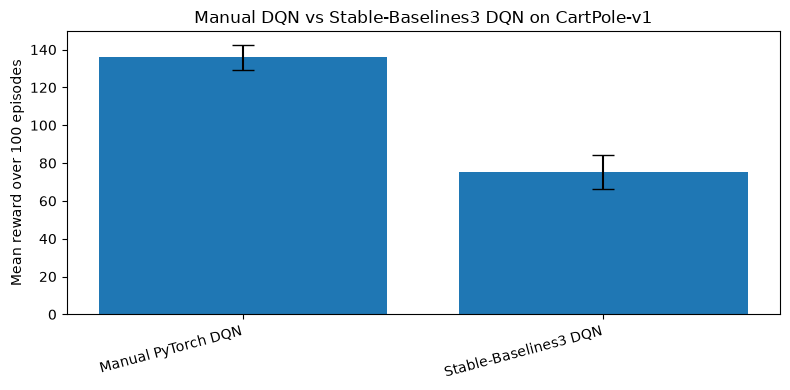

In [34]:
import gymnasium as gym
import numpy as np
import torch
import matplotlib.pyplot as plt

required_variables = ["policy_net", "manual_timesteps", "TRAINING_TIMESTEPS", "mean_reward", "std_reward"]
missing_variables = [name for name in required_variables if name not in globals()]
if missing_variables:
    raise RuntimeError(
        "Run the manual DQN training cell and the SB3 training/evaluation cell above first. "
        f"Missing variables: {missing_variables}"
    )

def evaluate_manual_dqn(policy_net, n_eval_episodes=100):
    eval_env = gym.make("CartPole-v1")
    rewards = []

    policy_net.eval()
    for _ in range(n_eval_episodes):
        state, info = eval_env.reset()
        state = torch.tensor(state, dtype=torch.float32, device=device).unsqueeze(0)
        episode_reward = 0.0
        done = False

        while not done:
            with torch.no_grad():
                action = policy_net(state).max(1).indices.view(1, 1)

            observation, reward, terminated, truncated, info = eval_env.step(action.item())
            episode_reward += reward
            done = terminated or truncated

            if not done:
                state = torch.tensor(observation, dtype=torch.float32, device=device).unsqueeze(0)

        rewards.append(episode_reward)

    eval_env.close()
    policy_net.train()
    return float(np.mean(rewards)), float(np.std(rewards))

manual_mean_reward, manual_std_reward = evaluate_manual_dqn(policy_net, n_eval_episodes=100)
manual_timesteps = int(manual_timesteps)

# Save the manual PyTorch model separately from the SB3 .zip model.
torch.save(policy_net.state_dict(), "manual_dqn_cartpole.pt")

# These variables are produced by the SB3 cell above.
sb3_mean_reward = float(mean_reward)
sb3_std_reward = float(std_reward)

comparison_rows = [
    {
        "agent": "Manual PyTorch DQN",
        "training_budget": f"{manual_timesteps} env steps",
        "mean_reward_100_eval_episodes": manual_mean_reward,
        "std_reward_100_eval_episodes": manual_std_reward,
        "saved_model": "manual_dqn_cartpole.pt",
    },
    {
        "agent": "Stable-Baselines3 DQN",
        "training_budget": f"{TRAINING_TIMESTEPS} env steps",
        "mean_reward_100_eval_episodes": sb3_mean_reward,
        "std_reward_100_eval_episodes": sb3_std_reward,
        "saved_model": "dqn_cartpole.zip",
    },
]

print(f"{'Agent':<25} | {'Training budget':<43} | {'Mean reward':>11} | {'Std':>7} | Saved model")
print('-' * 115)
for row in comparison_rows:
    print(
        f"{row['agent']:<25} | "
        f"{row['training_budget']:<43} | "
        f"{row['mean_reward_100_eval_episodes']:>11.2f} | "
        f"{row['std_reward_100_eval_episodes']:>7.2f} | "
        f"{row['saved_model']}"
    )

labels = [row["agent"] for row in comparison_rows]
means = [row["mean_reward_100_eval_episodes"] for row in comparison_rows]
stds = [row["std_reward_100_eval_episodes"] for row in comparison_rows]

plt.figure(figsize=(8, 4))
plt.bar(labels, means, yerr=stds, capsize=8)
plt.ylabel("Mean reward over 100 episodes")
plt.title("Manual DQN vs Stable-Baselines3 DQN on CartPole-v1")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()